In [1]:
from src.ColorsAnalysis import *
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from IPython.display import clear_output
from src.fss_collapse_core import collapse_for_c, fit_linear_feedback_model, label
from src.stability_tests import read_dynamic_bundle
from src.ColorsAnalysis import get_ft_min_max
#from src.TimeSeriesAnalysis import plot_article_fss
from matplotlib.ticker import FormatStrFormatter
plt.style.use('properties.mplstyle')

In [2]:
n_lst = [2]

for n in n_lst:
    
    results_folder = f"../results/{n}Color/2D"
    configurations_folder = results_folder + "/configurations"
    create_folder(results_folder)
    create_folder(configurations_folder)

Folder already exists: ../results/2Color/2D
Folder already exists: ../results/2Color/2D/configurations


In [3]:
df_dynamic = pd.read_csv("../SOP_data/all_colors_dynamic.dat", sep=' ')
df_dynamic

,type_perc,dim,L,f_T,c,num_colors,P0,p0,control_rule,N_samples,rho,nc,nc_err,nc_std,stat_window,stop_criterion,t_eq_validation,t_eq_s_prime_threshold,equilibrium_effective_rel_tol,post_equilibrium_extra_steps
0,bond,2,512,0.01,0.01,1,0.2,0.8,linear,702,1.00000,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
1,bond,2,512,0.01,0.01,1,0.2,0.8,relative,702,1.00000,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
2,bond,2,512,0.01,0.01,1,0.8,0.8,relative,702,1.00000,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
3,bond,2,1024,0.01,0.01,1,0.2,0.8,linear,502,1.00000,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
4,bond,2,1024,0.01,0.01,1,0.2,0.8,relative,502,1.00000,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7485,node,2,512,0.30,0.05,3,0.2,0.8,linear,701,0.33333,3.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0
7486,node,2,1024,0.30,0.05,3,0.2,0.8,linear,501,0.33333,3.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0
7487,node,2,2048,0.30,0.05,3,0.2,0.8,linear,401,0.33333,3.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0
7488,node,2,4096,0.30,0.05,3,0.2,0.8,linear,201,0.33333,3.0,0.0,0.0,0,alive_species_pt_derivative_stability_or_death,global_tail_drift_validation_of_blocked_pt_var...,0.00001,0.025,100.0


In [4]:
control_rule = 'linear'  # use 'linear' para analisar a regra linear
df_series = pd.read_csv('../SOP_data/all_data_dynamic.dat', sep=r'\s+')
df_series

,type_perc,dim,L,f_T,c,nc,rho,p0,P0,control_rule,...,p_err,f_mean,f_err,z_stat_mean,z_stat_err,z_stat_median,z_stat_q75,z_stat_q90,t_eq_validation,t_eq_s_prime_threshold
0,bond,2,4096,0.020000,0.01,1,1.00000,0.8,0.02,relative,...,0.000376,0.020000,3.305353e-07,4096.500000,0.500000,4096.5,4096.75,4096.9,global_tail_drift_validation_of_blocked_pt_var...,0.00001
1,bond,2,2048,0.025263,0.01,1,1.00000,0.8,0.80,relative,...,0.000000,0.025250,0.000000e+00,2050.000000,0.000000,2050.0,2050.00,2050.0,NaN,NaN
2,bond,2,4096,0.025263,0.01,1,1.00000,0.8,0.20,relative,...,0.000261,0.025264,3.673398e-06,4100.200000,1.157584,4101.0,4102.00,4102.6,NaN,NaN
3,bond,2,4096,0.025263,0.01,1,1.00000,0.8,0.80,relative,...,0.000376,0.025269,1.266400e-05,4098.750000,1.314978,4099.0,4101.00,4101.0,NaN,NaN
4,bond,2,8192,0.025263,0.01,1,1.00000,0.8,0.20,linear,...,0.000097,0.025257,4.488178e-06,8195.571429,0.922139,8196.0,8197.00,8197.8,global_tail_drift_validation_of_blocked_pt_var...,0.00001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7481,node,2,4096,0.300000,0.05,3,0.33333,0.8,0.20,linear,...,0.000036,0.299514,2.094248e-06,4099.756219,0.194006,4099.0,4102.00,4104.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001
7482,node,2,4096,0.300000,0.05,3,0.33333,0.8,0.20,linear,...,0.000034,0.299536,1.814213e-06,4099.781095,0.194602,4099.0,4102.00,4104.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001
7483,node,2,8192,0.300000,0.05,3,0.33333,0.8,0.20,linear,...,0.000029,0.299228,1.757805e-06,8197.009901,0.258516,8197.0,8199.00,8200.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001
7484,node,2,8192,0.300000,0.05,3,0.33333,0.8,0.20,linear,...,0.000029,0.299241,1.518876e-06,8196.643564,0.246393,8197.0,8198.00,8200.0,global_tail_drift_validation_of_blocked_pt_var...,0.00001


In [16]:
round(1/3,5)
df_series[df_series['nc'] == 3]['rho']


3481    0.33333
3482    0.33333
3483    0.33333
3484    0.33333
3485    0.33333
         ...   
7481    0.33333
7482    0.33333
7483    0.33333
7484    0.33333
7485    0.33333
Name: rho, Length: 516, dtype: float64

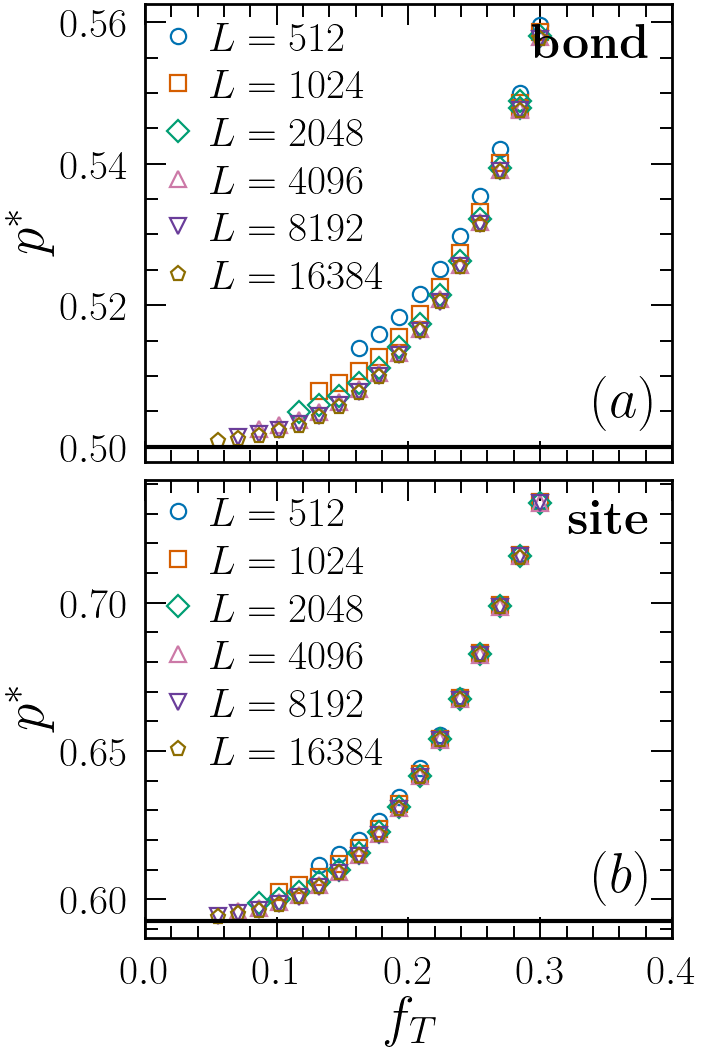

In [20]:
L_lst = [512, 1024, 2048, 4096, 8192, 16384]

nc = 2
rho = round(1 / nc, 5)

order = 0
p0 = 0.8
dim = 2
c = 0.05
P0 = 0.2
control_rule = 'linear'

markers = ['o', 's', 'D', '^', 'v', 'p']
colors = [
    '#0072B2',  # azul
    '#D55E00',  # laranja avermelhado
    '#009E73',  # verde
    '#CC79A7',  # magenta
    '#6A3D9A',  # roxo
    '#8C6D00',  # amarelo-ouro escuro
]
    
base = 7
fs_l_fig = 40
fs_label = 40
type_perc_lst = ['bond', 'site']
pc_dict = {'bond': 0.5, 'site': 0.59274605079016}
labels = [r'$(a)$', r'$(b)$']

fig, axes = plt.subplots(
    2, 1,
    figsize=(base, 1.5 * base),
    constrained_layout=True,
    sharex=True,
)
aux = []
ms = 11
mew = 1.6
for idx_type, type_perc in enumerate(type_perc_lst):
    ax = axes[idx_type]
    # No DataFrame, percolação por sítio está armazenada como "node".
    type_perc_df = 'node' if type_perc == 'site' else type_perc
    pc = pc_dict[type_perc]

    for idx_L, L in enumerate(L_lst):
        df_sub = df_series[
            (df_series['type_perc'] == type_perc_df)
            & (df_series['p0'] == p0)
            & (df_series['order'] == order)
            & (df_series['rho'] == rho)
            & (df_series['nc'] == nc)
            & (df_series['L'] == L)
            & (df_series['c'] == c)
            & (df_series['dim'] == dim)
            & (df_series['P0'] == P0)
            & (df_series['control_rule'] == control_rule)
        ].sort_values('f_T').reset_index(drop=True)

        df_filter = df_sub[
            (0.98 * df_sub['N_samples']) <= df_sub['N_samples_perc']
        ]
        df_plot = df_filter.sort_values('f_T').copy()
        df_plot = df_plot[
            (df_plot['p_mean'] >= 0) & (df_plot['p_mean'] <= 1)
            & (df_plot['N_samples_perc'] >= 5)
            & (df_plot['p_mean'] < 0.9)
        ]
        df_trunc = df_plot[df_plot['f_T'] <= 0.4].copy()
        x = df_trunc['f_T']
        y = df_trunc['p_mean']
        y_err = df_trunc['p_err']
        
        if len(x) > 0:
            row_ft_min = df_trunc.loc[df_trunc['f_T'].idxmin()]
            aux.append((row_ft_min['f_T'], L, c, idx_type))

        ax.plot(
            x, y, markers[idx_L], ms=ms, mew=mew,
            color=colors[idx_L], label=fr'$L={L}$'
        )
        #ax.errorbar(x=x,y=y,yerr=y_err,ms=ms, marker=markers[idx_L])

    ax.annotate(
        fr'$\mathbf{{{type_perc}}}$',
        xy=(0.98, 0.91), xycoords='axes fraction',
        xytext=(-8, 0), textcoords='offset points',
        ha='right', va='center', fontsize=35,
    )
    ax.text(
        0.85, 0.10, labels[idx_type],
        transform=ax.transAxes, fontsize=fs_l_fig,
    )
    ax.axhline(y=pc, color='k', linestyle='-', linewidth=3.0)
    ax.set_xlim(0.0, 0.4)
    ax.set_ylabel(r'$p^*$', fontsize=fs_label)
    ax.legend(loc='best', fontsize=30)
    ax.tick_params(axis='both', which='major', width=1.4, length=15, labelsize=30, pad=12)
    ax.tick_params(axis='both', which='minor', width=1.4, length=9, labelsize=30, pad=12)
    
    # if(type_perc=='bond'):
    #     ax.set_ylim(0.495, 0.515)
    # else:
    #     ax.set_ylim(0.585,  0.62)

    if idx_type == 1:
        ax.set_xlabel(r'$f_T$', fontsize=fs_label)

#plt.savefig(f'../results/{nc}Color/2D/pstar_vs_ft_2D.pdf')
plt.show()

vec = np.array(aux, dtype=float)
if len(vec) > 0:
    # Ordena primeiro pelo tipo de percolação, depois por L.
    index = np.lexsort((vec[:, 1], vec[:, 3]))
    triplas_ordenadas = vec[index]
    np.set_printoptions(suppress=True)


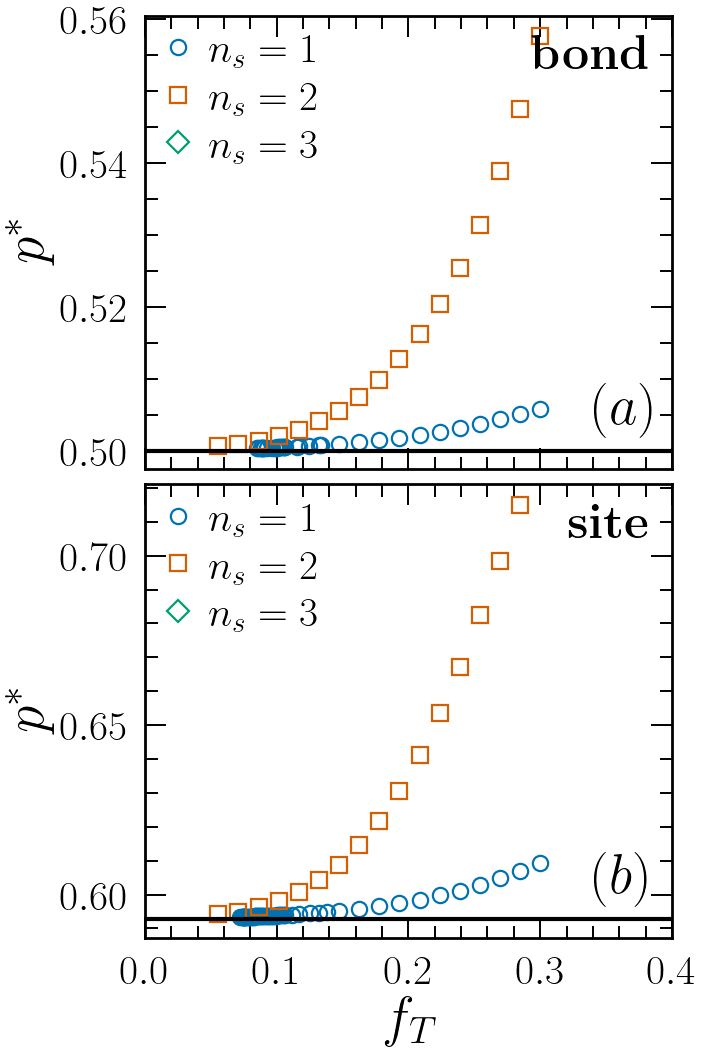

In [19]:
#L_lst = [512, 1024, 2048, 4096, 8192, 16384]
L = 16384
nc_lst = [1,2, 3]

order = 0
p0 = 0.8
dim = 2
c = 0.05
P0 = 0.2
control_rule = 'linear'

markers = ['o', 's', 'D', '^', 'v', 'p']
colors = [
    '#0072B2',  # azul
    '#D55E00',  # laranja avermelhado
    '#009E73',  # verde
    '#CC79A7',  # magenta
    '#6A3D9A',  # roxo
    '#8C6D00',  # amarelo-ouro escuro
]
    
base = 7
fs_l_fig = 40
fs_label = 40
type_perc_lst = ['bond', 'site']
pc_dict = {'bond': 0.5, 'site': 0.59274605079016}
labels = [r'$(a)$', r'$(b)$']

fig, axes = plt.subplots(
    2, 1,
    figsize=(base, 1.5 * base),
    constrained_layout=True,
    sharex=True,
)
aux = []
ms = 11
mew = 1.6
for idx_type, type_perc in enumerate(type_perc_lst):
    ax = axes[idx_type]
    # No DataFrame, percolação por sítio está armazenada como "node".
    type_perc_df = 'node' if type_perc == 'site' else type_perc
    pc = pc_dict[type_perc]

    for idx_nc, nc in enumerate(nc_lst):
        rho = round(1 / nc, 5)
        df_sub = df_series[
            (df_series['type_perc'] == type_perc_df)
            & (df_series['p0'] == p0)
            & (df_series['order'] == order)
            & (df_series['rho'] == rho)
            & (df_series['nc'] == nc)
            & (df_series['L'] == L)
            & (df_series['c'] == c)
            & (df_series['dim'] == dim)
            & (df_series['P0'] == P0)
            & (df_series['control_rule'] == control_rule)
        ].sort_values('f_T').reset_index(drop=True)

        df_filter = df_sub[
            (0.98 * df_sub['N_samples']) <= df_sub['N_samples_perc']
        ]
        df_plot = df_filter.sort_values('f_T').copy()
        df_plot = df_plot[
            (df_plot['p_mean'] >= 0) & (df_plot['p_mean'] <= 1)
            & (df_plot['N_samples_perc'] >= 5)
            & (df_plot['p_mean'] < 0.9)
        ]
        df_trunc = df_plot[df_plot['f_T'] <= 0.4].copy()
        x = df_trunc['f_T']
        y = df_trunc['p_mean']
        y_err = df_trunc['p_err']
        
        if len(x) > 0:
            row_ft_min = df_trunc.loc[df_trunc['f_T'].idxmin()]
            aux.append((row_ft_min['f_T'], L, c, idx_type))

        ax.plot(
            x, y, markers[idx_nc], ms=ms, mew=mew,
            color=colors[idx_nc], label=fr'$n_s={nc}$'
        )
        #ax.errorbar(x=x,y=y,yerr=y_err,ms=ms, marker=markers[idx_L])

    ax.annotate(
        fr'$\mathbf{{{type_perc}}}$',
        xy=(0.98, 0.91), xycoords='axes fraction',
        xytext=(-8, 0), textcoords='offset points',
        ha='right', va='center', fontsize=35,
    )
    ax.text(
        0.85, 0.10, labels[idx_type],
        transform=ax.transAxes, fontsize=fs_l_fig,
    )
    ax.axhline(y=pc, color='k', linestyle='-', linewidth=3.0)
    ax.set_xlim(0.0, 0.4)
    ax.set_ylabel(r'$p^*$', fontsize=fs_label)
    ax.legend(loc='best', fontsize=30)
    ax.tick_params(axis='both', which='major', width=1.4, length=15, labelsize=30, pad=12)
    ax.tick_params(axis='both', which='minor', width=1.4, length=9, labelsize=30, pad=12)
    
    # if(type_perc=='bond'):
    #     ax.set_ylim(0.495, 0.515)
    # else:
    #     ax.set_ylim(0.585,  0.62)

    if idx_type == 1:
        ax.set_xlabel(r'$f_T$', fontsize=fs_label)

plt.savefig(f'../results/COLORS_pstar_vs_ft_2D.pdf')
plt.show()

vec = np.array(aux, dtype=float)
if len(vec) > 0:
    # Ordena primeiro pelo tipo de percolação, depois por L.
    index = np.lexsort((vec[:, 1], vec[:, 3]))
    triplas_ordenadas = vec[index]
    np.set_printoptions(suppress=True)

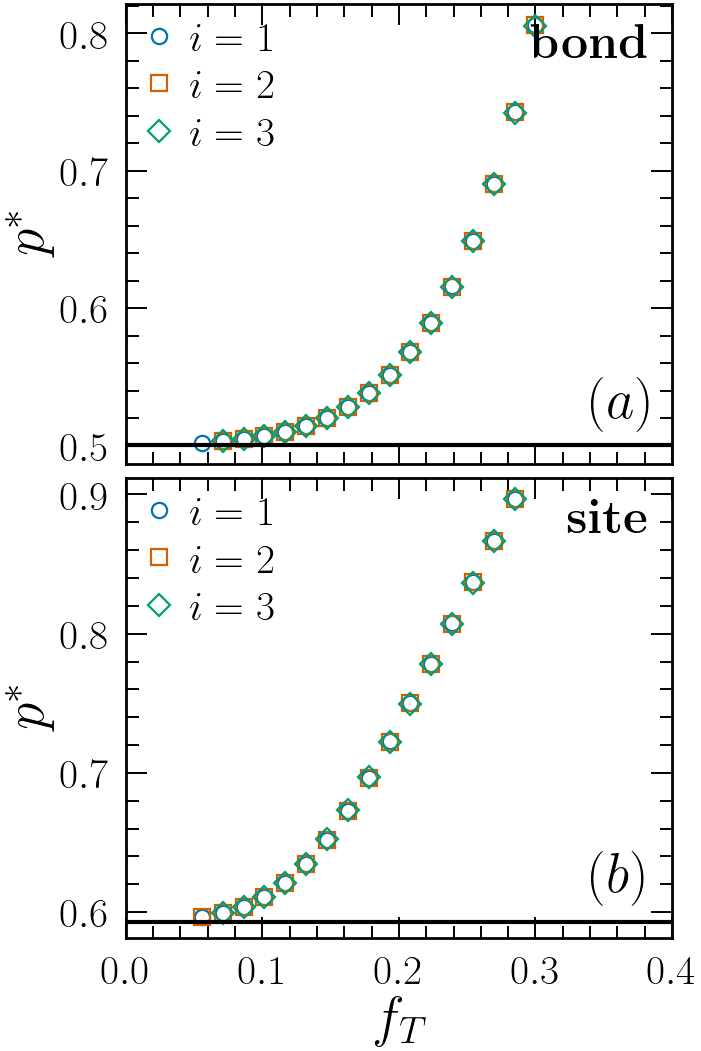

In [23]:
#L_lst = [512, 1024, 2048, 4096, 8192, 16384]
L = 8192
nc = 3

order = 0
p0 = 0.8
dim = 2
c = 0.05
P0 = 0.2
control_rule = 'linear'

markers = ['o', 's', 'D', '^', 'v', 'p']
colors = [
    '#0072B2',  # azul
    '#D55E00',  # laranja avermelhado
    '#009E73',  # verde
    '#CC79A7',  # magenta
    '#6A3D9A',  # roxo
    '#8C6D00',  # amarelo-ouro escuro
]
    
base = 7
fs_l_fig = 40
fs_label = 40
type_perc_lst = ['bond', 'site']
pc_dict = {'bond': 0.5, 'site': 0.59274605079016}
labels = [r'$(a)$', r'$(b)$']
orders_lst = [i for i in range(nc)]
fig, axes = plt.subplots(
    2, 1,
    figsize=(base, 1.5 * base),
    constrained_layout=True,
    sharex=True,
)
aux = []
ms = 11
mew = 1.6
for idx_type, type_perc in enumerate(type_perc_lst):
    ax = axes[idx_type]
    # No DataFrame, percolação por sítio está armazenada como "node".
    type_perc_df = 'node' if type_perc == 'site' else type_perc
    pc = pc_dict[type_perc]

    for idx_order, order in enumerate(orders_lst):
        rho = round(1 / nc, 5)
        df_sub = df_series[
            (df_series['type_perc'] == type_perc_df)
            & (df_series['p0'] == p0)
            & (df_series['order'] == order)
            & (df_series['rho'] == rho)
            & (df_series['nc'] == nc)
            & (df_series['L'] == L)
            & (df_series['c'] == c)
            & (df_series['dim'] == dim)
            & (df_series['P0'] == P0)
            & (df_series['control_rule'] == control_rule)
        ].sort_values('f_T').reset_index(drop=True)

        df_filter = df_sub[
            (0.98 * df_sub['N_samples']) <= df_sub['N_samples_perc']
        ]
        df_plot = df_filter.sort_values('f_T').copy()
        df_plot = df_plot[
            (df_plot['p_mean'] >= 0) & (df_plot['p_mean'] <= 1)
            & (df_plot['N_samples_perc'] >= 5)
            & (df_plot['p_mean'] < 0.9)
        ]
        df_trunc = df_plot[df_plot['f_T'] <= 0.4].copy()
        x = df_trunc['f_T']
        y = df_trunc['p_mean']
        y_err = df_trunc['p_err']
        
        if len(x) > 0:
            row_ft_min = df_trunc.loc[df_trunc['f_T'].idxmin()]
            aux.append((row_ft_min['f_T'], L, c, idx_type))

        ax.plot(
            x, y, markers[idx_order], ms=ms, mew=mew,
            color=colors[idx_order], label=fr'$i={idx_order+1}$'
        )
        #ax.errorbar(x=x,y=y,yerr=y_err,ms=ms, marker=markers[idx_L])

    ax.annotate(
        fr'$\mathbf{{{type_perc}}}$',
        xy=(0.98, 0.91), xycoords='axes fraction',
        xytext=(-8, 0), textcoords='offset points',
        ha='right', va='center', fontsize=35,
    )
    ax.text(
        0.85, 0.10, labels[idx_type],
        transform=ax.transAxes, fontsize=fs_l_fig,
    )
    ax.axhline(y=pc, color='k', linestyle='-', linewidth=3.0)
    ax.set_xlim(0.0, 0.4)
    ax.set_ylabel(r'$p^*$', fontsize=fs_label)
    ax.legend(loc='best', fontsize=30)
    ax.tick_params(axis='both', which='major', width=1.4, length=15, labelsize=30, pad=12)
    ax.tick_params(axis='both', which='minor', width=1.4, length=9, labelsize=30, pad=12)
    
    # if(type_perc=='bond'):
    #     ax.set_ylim(0.495, 0.515)
    # else:
    #     ax.set_ylim(0.585,  0.62)

    if idx_type == 1:
        ax.set_xlabel(r'$f_T$', fontsize=fs_label)

plt.savefig(f'../results/ORDERS_pstar_vs_ft_2D.pdf')
plt.show()

vec = np.array(aux, dtype=float)
if len(vec) > 0:
    # Ordena primeiro pelo tipo de percolação, depois por L.
    index = np.lexsort((vec[:, 1], vec[:, 3]))
    triplas_ordenadas = vec[index]
    np.set_printoptions(suppress=True)
